# Exploration of SINAN Dengue dataset
The aim of this notebook is to get an idea of what the dengue data looks like and to get a 'feel' for it. The raw data was downloaded from [Kaggle](https://www.kaggle.com/datasets/gallo33henrique/dengue-no-brasil-sinan-20002025) and saved in `data/SINAN_data` (see the README). 

I am only looking at years 2001 - 2019 since the year 2000 had very low data quality and I wanted to avoid the Covid pandemic years, which would likely be very anomalous.

Implementation notes:
- Computations often done in their own cells, separate to plotting, so changes in plots/display do not require re-running a computationally intensive cell
- Functions reused across notebooks are in `visualize.py` and `pipeline_funcs.py` so they can be easily imported

In [1]:
%load_ext autoreload
%autoreload 2

import polars as pl # use pl.__version__ to check version
import pathlib as Path
import matplotlib.pyplot as plt
import numpy as np

import pipeline_funcs as pf   # data loading / cleaning helpers
import visualize as viz       # plotting helpers

## Loading data
The data is loaded using Polars' `scan csv` which avoids storing all the files in memory since they are very large. Using LazyFrames, computations are only evaluated when the results are needed, meaning operations on lazyframes build query plans which are only executed when I call `.collect()`. This has been a lifesaver, but is occasionally inconvenient due to Polars' relatively limited compatibility with other libraries such as matplotlib.

Important choices:
- `schema_overrides={"NDUPLIC": pl.String, "NDUPLIC_N": pl.Int64}`: forces these columns into these specific types, which Polars struggled to infer. `NDUPLIC` has to be a string because it contains alphanumeric values. 
- `ignore_errors=True`: means erroneous records are skipped, which I can afford since I have such a large dataset
- `infer_schema_length=10000`: by default it is 100, but given the size of my dataset, I increased this value to improve the type guessing (the default value was causing issues as some columns can have both letters and numbers)

In [2]:
full_lf_dict = pf.load_dengue_data() # one lazy frame per year in pf.DEFAULT_YEARS (2001-2019)
print(full_lf_dict)

{'2001': <LazyFrame at 0x21CD7339010>, '2002': <LazyFrame at 0x21CD7395450>, '2003': <LazyFrame at 0x21CD7395590>, '2004': <LazyFrame at 0x21CD72A3100>, '2005': <LazyFrame at 0x21CD72A3490>, '2006': <LazyFrame at 0x21CD7308DD0>, '2007': <LazyFrame at 0x21CD72C2E00>, '2008': <LazyFrame at 0x21CD72C2F10>, '2009': <LazyFrame at 0x21CD72D2B50>, '2010': <LazyFrame at 0x21CD72D2450>, '2011': <LazyFrame at 0x21CD72B6F30>, '2012': <LazyFrame at 0x21CD72B7200>, '2013': <LazyFrame at 0x21CD73B0AD0>, '2014': <LazyFrame at 0x21CD73B0BB0>, '2015': <LazyFrame at 0x21CD735B2B0>, '2016': <LazyFrame at 0x21CD7217C50>, '2017': <LazyFrame at 0x21CD7217E90>, '2018': <LazyFrame at 0x21CD72BA4C0>, '2019': <LazyFrame at 0x21CD72BA8E0>}


## Column presence
Since the data spans so many years, it is important to check how consistently the columns appear, and if they are encoded the same way across years. Sometimes columns may have identical names for every year but be encoded differently over time.

In [3]:
# year x column presence matrix; fully_present = columns present in every year
wide, fully_present = pf.column_presence(full_lf_dict)

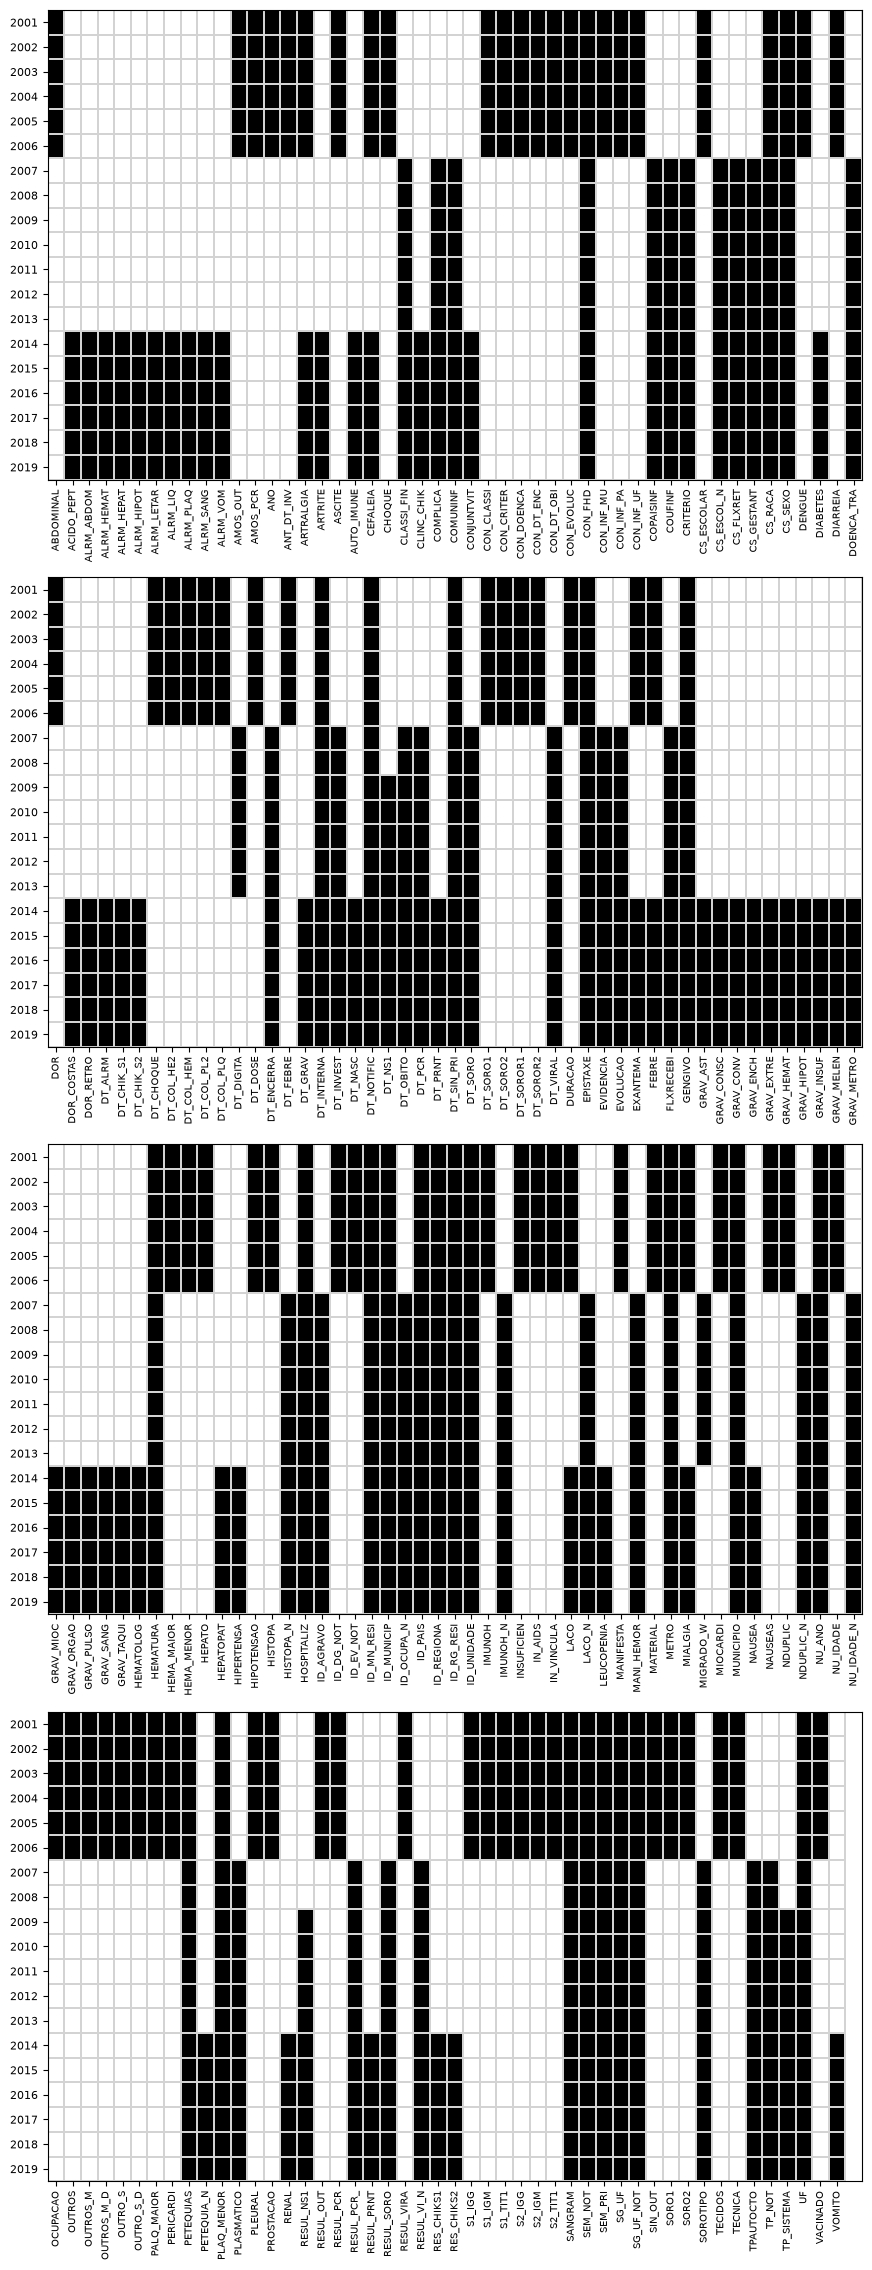

In [4]:
# heatmap of column presence per year; raise n_panels to spread columns over more rows
fig, axes = viz.plot_column_presence(wide, n_panels=4)
plt.show()

Clearly there is significant inconsistency across years, with system changes from 2006 to 2007, and 2013 to 2014, clearly marked. However, for temporal predictions, many variables are irrelevant (eg, clinical symptoms) so it is not worth investigating them further. I decided to reduce down to what actually looks most useful.

In [5]:
# after manually inspecting data dictionary, came up with these as a start point
columns_of_interest = {
    "TP_NOT", # type of notification - 2 = "individual"
    "DT_NOTIFIC", # date of notification
    "NU_ANO", # year, should correspond to filename
    "SG_UF_NOT", # state code where notification processed
    "ID_MUNICIP", # municipality code
    "ID_REGIONA", # region code
    "ID_PAIS", # country of residence of patient
    "DT_INVEST", # start of investigation of case
    "COUFINF", # state in which patient was probably infected
    "COPAISINF", # country in which patient was probably infected
    "CLASSI_FIN", # case classification: confirmado / inconclusivo / ignorado - 0 and 9 are nulls here
    "CRITERIO", # criterion used to reach classification - 0 and 9 are nulls here
    "EVOLUCAO", # how the case evolved (ie recovery or cause of death) - 9 is a null here
    "NDUPLIC_N", # identifies whether it is a duplicate entry (value 2) - 0 corresponds to 'not identified'
}


In [6]:
# the ones I don't need to look for alternative names for
print("The following columns of interest are present in all files:")
fully_present_interest = sorted(set(fully_present).intersection(columns_of_interest))
print(fully_present_interest)

print("The following columns of interest do not appear in all files:")
print(sorted(columns_of_interest - (set(fully_present))))

The following columns of interest are present in all files:
['DT_NOTIFIC', 'ID_MUNICIP', 'ID_PAIS', 'ID_REGIONA', 'NU_ANO', 'SG_UF_NOT']
The following columns of interest do not appear in all files:
['CLASSI_FIN', 'COPAISINF', 'COUFINF', 'CRITERIO', 'DT_INVEST', 'EVOLUCAO', 'NDUPLIC_N', 'TP_NOT']


### Understanding missingness
Here I tried to narrow down further the number of columns to investigate. So for each year, I am interested in:
- Whether the column of interest is present
- Number of null values (including '0' and '9' which denote 'ignorado')
---
When present it is also useful to know:
- Number of confirmed cases per year, as a percentage of total reported cases
---
Then I will run it again, but filtering out irrelevant information such as:
- Probable infections outside of Brazil
- TP_NOT that is not just 'individual'; I just want to look at individual cases
- Cases where year input does not correspond to filename

#### How the coverage summary works (`check_coverage`)
For each year, `pf.check_coverage` describes the whole summary as a lazy query that produces a single row: the percentage of missing values for every column of interest, plus the percentage of confirmed cases. The cell below tags each row with its year and stacks them into one table (one row per year). Key design decisions:

- **Percentages as the mean of a boolean column.** `is_null()` and `is_in(...)` turn a column into True/False values, and its mean will just be the proportion of `True`'s. This avoids a separate query just to count the rows, so every percentage is a single expression.
- **One pass over each file.** Missingness and the confirmed-case percentage are computed in the same query, for performance.
- **Convert from codes to truly null values** Before measuring missingness, codes such as 0 and 9 ("ignorado") are converted to real nulls using `pf.DEFAULT_NULL_DICT`. Some columns encode missing values with a code rather than an empty field, and `pf.DEFAULT_NULL_DICT` describes these null codes for the relevant columns according to given column descriptions. Columns in the dictionary that don't exist in a given year's file are skipped, since many columns changed with the 2007 and 2014 system changes.
- **Absent columns get −1.** A column that doesn't exist in a year gets a presence of 0 and a missingness of −1, meaning "not in this file", to distinguish between an existing empty column and a column that didn't exist that year. These values thus cannot be compared as if they were real percentages.
- **Confirmed cases from both systems' classification columns.** The 2007 system change introduced a different (or renamed) classification column: it is `CON_CLASSI` before 2007 and `CLASSI_FIN` from 2007. The loop picks the right one for each year, and confirmed cases are codes 1, 10, 11, 12 in both. This is an assumption based on the checks done in *Dealing with system changes*, below.
- **Missing classifications stay in the denominator.** For a missing value, `is_in` returns null rather than False, and `mean()` skips nulls, which would compute the percentage over classified rows only. `fill_null(False)` counts missing rows as "not confirmed", so the result is the share of all notifications that are confirmed dengue.

In [7]:
# concatenate everything into big dataframes containing the information for all years
presence_frames, coverage_frames = [], []
for yr_str, lf in full_lf_dict.items():
    class_col = "CON_CLASSI" if int(yr_str) < 2007 else "CLASSI_FIN"
    presence, coverage = pf.check_coverage(
        lf, columns_of_interest, nulls_dict=pf.DEFAULT_NULL_DICT,
        count_column=class_col, count_values=pf.DENGUE_CONFIRMADO, count_alias="pct_confirmed",
    )
    presence_frames.append(presence.with_columns(pl.lit(yr_str).alias("year")))
    coverage_frames.append(coverage.with_columns(pl.lit(yr_str).alias("year"), pl.lit(class_col).alias("classification_column")))

presence_summary = pl.concat(presence_frames, how="vertical")
coverage_summary_df = pl.concat(coverage_frames, how="vertical").collect()

In [8]:
# confirmed cases (codes 1, 10, 11, 12) as a percentage of ALL notifications in the year, for every year;
# classification_column shows which system's column each year's value comes from
confirmed_summary_df = coverage_summary_df.select("year", "pct_confirmed", "classification_column")
confirmed_summary_df.write_csv(pf.OUTPUT_DIR / "confirmed_summary.csv")
confirmed_summary_df

year,pct_confirmed,classification_column
str,f64,str
"""2001""",58.364477,"""CON_CLASSI"""
"""2002""",52.827522,"""CON_CLASSI"""
"""2003""",53.770322,"""CON_CLASSI"""
"""2004""",45.811627,"""CON_CLASSI"""
"""2005""",48.560426,"""CON_CLASSI"""
…,…,…
"""2015""",57.958308,"""CLASSI_FIN"""
"""2016""",47.934004,"""CLASSI_FIN"""
"""2017""",32.325843,"""CLASSI_FIN"""


In [9]:
presence_summary_df = presence_summary.collect()
presence_summary_df.write_csv(pf.OUTPUT_DIR / "presence_summary.csv")
presence_summary_df

CLASSI_FIN,COPAISINF,COUFINF,CRITERIO,DT_INVEST,DT_NOTIFIC,EVOLUCAO,ID_MUNICIP,ID_PAIS,ID_REGIONA,NDUPLIC_N,NU_ANO,SG_UF_NOT,TP_NOT,year
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,"""2001"""
0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,"""2002"""
0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,"""2003"""
0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,"""2004"""
0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,"""2005"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"""2015"""
1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"""2016"""
1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,"""2017"""


In [10]:
nulls_summary_df = coverage_summary_df.drop("pct_confirmed", "classification_column") # % missing per column of interest (-1 = column not in that year's file)
nulls_summary_df.write_csv(pf.OUTPUT_DIR / "nulls_summary.csv")

In [11]:
nulls_summary_df.show(limit=20)

CLASSI_FIN,COPAISINF,COUFINF,CRITERIO,DT_INVEST,DT_NOTIFIC,EVOLUCAO,ID_MUNICIP,ID_PAIS,ID_REGIONA,NDUPLIC_N,NU_ANO,SG_UF_NOT,TP_NOT,year
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
-1.0,-1.0,-1.0,-1.0,-1.0,0.0,-1.0,0.0,0.000614,20.685851,-1.0,0.0,1.516609,-1.0,"""2001"""
-1.0,-1.0,-1.0,-1.0,-1.0,0.0,-1.0,0.0,0.007246,32.809753,-1.0,0.0,1.209908,-1.0,"""2002"""
-1.0,-1.0,-1.0,-1.0,-1.0,0.0,-1.0,0.0,0.0,8.459011,-1.0,0.0,0.930369,-1.0,"""2003"""
-1.0,-1.0,-1.0,-1.0,-1.0,0.0,-1.0,0.0,0.0,13.70966,-1.0,0.0,1.163173,-1.0,"""2004"""
-1.0,-1.0,-1.0,-1.0,-1.0,0.0,-1.0,0.000382,0.0,8.676066,-1.0,0.0,0.089101,-1.0,"""2005"""
-1.0,-1.0,-1.0,-1.0,-1.0,0.0,-1.0,0.0,0.0,14.143768,-1.0,0.0,0.001946,-1.0,"""2006"""
2.025946,0.0,48.913466,20.518284,17.622999,0.0,53.370604,0.0,0.002371,14.958088,87.764696,0.0,0.000418,0.0,"""2007"""
3.447316,0.0,56.546876,25.367988,19.419051,0.0,60.181612,0.000109,0.002828,33.180141,99.224104,0.000109,0.000109,0.0,"""2008"""
2.911307,0.0,44.44709,16.193075,9.693536,0.0,48.449534,0.0,0.0,6.755591,99.16708,0.0,0.0,0.0,"""2009"""


##### What to do with columns:
Any columns with missingness higher than 30% anywhere are dropped. What is likely to be most useful here is `DT_NOTIFIC`, the date of notification, which has nearly no missing values, and `SG_UF_NOT`, which encodes the state, also with very low missingness. Other spatial resolutions are possible, for example using municipality instead; `ID_MUNICIP`. `ID_REGIONA` unfortunately has more missing values so I'd prefer not to use that one. With the columns I am using, since they have low missingness and I have a lot of data, I've decided to just drop the values.

Missingness
- ``COUFINF`` (remove, make the assumption that people were infected in their place of residence; probably true in vast majority of cases)
- ``NDUPLIC_N`` - only the value 2 is important (duplicate), don't care about missing values
- ``EVOLUCAO`` (remove, not that informative)

Cleaning
- ``ID_PAIS`` - Not clear where codes are from but mostly 1, so 1 = Brazil. Exclude everything else.


### Checking geographical changes
State names are probably consistent, I would expect municipalities to have changed a little. Here I want to check how municipalities changed over time; which were added, removed, etc.

I am using ``ID_MUNICIP`` due to low missingness.

> Note: I had to ask an AI bot to correct the names of the municipalities as the CSV (even when directly downloaded off the website of the Brazilian government!) had missing letters, probably due to accents being stored incorrectly (so, eg, 'São João' -> 'So Joo'). I know this can introduce errors but I think they are mostly minor enough to not be considered significant. The bot used a website, which displayed a table of all the municipality names and codes, to perform this task, so didn't just fill things from memory. 

In [12]:
# get only the IBGE codes and names (the relevant part), and keep UF (state) string since a name may not be unique

municipality_codes = pf.load_municipality_codes()
municipality_codes

CÓDIGO DO MUNICÍPIO - IBGE,MUNICÍPIO - IBGE,UF
i64,str,str
1100106,"""Guajará-Mirim""","""RO"""
1100379,"""Alto Alegre dos Parecis""","""RO"""
1100205,"""Porto Velho""","""RO"""
1100452,"""Buritis""","""RO"""
1100122,"""Ji-Paraná""","""RO"""
…,…,…
4217550,"""Serra Alta""","""SC"""
4218756,"""Tunápolis""","""SC"""
5209457,"""Guarinos""","""GO"""


In [13]:
n_unique_municip = []
n_unique_states = []

for lf in full_lf_dict.values():
    # count number of unique municipalities, by code
    num_municip = lf.select(pl.col("ID_MUNICIP").drop_nulls().n_unique()).collect().item() # n_unique alone counts a missing code as a value
    num_states = lf.select(pl.col("SG_UF_NOT").drop_nulls().n_unique()).collect().item()
    # build a list of results for plotting
    n_unique_municip.append(num_municip)
    n_unique_states.append(num_states)


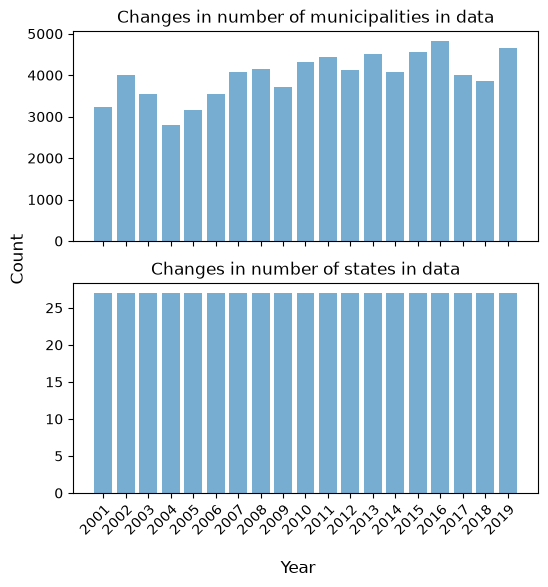

In [14]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6), sharex=True) 
years = [int(y) for y in pf.DEFAULT_YEARS]


ax1.bar(years, n_unique_municip, alpha=0.6)
ax2.bar(years, n_unique_states, alpha=0.6)


for ax in (ax1, ax2):
    ax.set_xticks(years)
# slant the year labels so they don't overlap; with sharex only the bottom plot shows them.
# ha="right" lines the end of each label up with its tick
ax2.tick_params(axis="x", labelrotation=45)
plt.setp(ax2.get_xticklabels(), ha="right", rotation_mode="anchor")


ax1.set_title("Changes in number of municipalities in data")
ax2.set_title("Changes in number of states in data")

fig.supxlabel("Year", y=-0.03), fig.supylabel("Count")
plt.show()  

The municipalities appear inconsistent across years, but since I'm using data from dengue reports, it might just be that in some years some municipalities had no reported cases, so from this I cannot distinguish between that and a municipality being removed or added. Since I'm probably going to work at the state-level first, I will leave this here for now.

For the states there seemed to be a change from 2008 to 2009 (from 28 to 27 unique values), but the check below shows that no state disappeared: the count included missing state codes as a value, and a few notifications up to 2008 have no state, while from 2009 none do. The same 27 states are present in both years, so the plot above now counts only real state codes.

In [15]:
# what changed between 2008 and 2009: the number of unique values including missing, the number of states, and missing states
for yr in ("2008", "2009"):
    print(yr, full_lf_dict[yr].select(pl.col("SG_UF_NOT").n_unique().alias("unique values incl. missing"), pl.col("SG_UF_NOT").drop_nulls().n_unique().alias("states"), pl.col("SG_UF_NOT").null_count().alias("rows without a state")).collect().row(0, named=True))

2008 {'unique values incl. missing': 28, 'states': 27, 'rows without a state': 1}
2009 {'unique values incl. missing': 27, 'states': 27, 'rows without a state': 0}


### Dealing with system changes
From 2006 to 2007, the system underwent a major change from SINAN Windows to the new SINAN Net system. The column names make this quite clear. I was not able to find the pre-2007 documentation of the names, so I've had to take an educated guess. 

This was done by manually inspecting the variables of interest, ie looking at how they are encoded, the number of unique values, etc.


1. ``CON_CLASSI`` <-> ``CLASSI_FIN``

    An integer from 1 to 8. The modern equivalent is probably ``CLASSI_FIN``, which also uses integers with 1, 2, and 3 denoting specific cases, and empty, 0 or 9 denoting an ignored case (equivalent to a null value). I don't have specific information on whether ``CON_CLASSI``'s integers map in similar ways, but it seems likely, given the results of the exploration below, especially given the semantic equivalence in the names.

    - confirmed cases only correspond to 1, 10, 11, 12. The number of codes changed throughout the years (for both)
    - the last check below compares the share of notifications coded as confirmed (1, 10, 11, 12) in each period. Similar shares support the assumption but don't prove it.


In [16]:
# This is just a scrappy check - does the number of codes (ie unique column values) change? Does their coverage change a lot?
for year_str in [y for y in pf.DEFAULT_YEARS if int(y) < 2007]:
    print(f"--------- Year {year_str} -----------")
    dengbr = full_lf_dict[year_str] 

    col_of_interest = "CON_CLASSI"
    # is_null().mean() divides by ALL rows (count() would only count the non-null ones)
    pct_null = dengbr.select(pl.col(col_of_interest).is_null().mean() * 100).collect().item()
    print("Percent null,", pct_null)

    # ----
    # Get all the unique values
    unique = dengbr.select(pl.col(col_of_interest).n_unique()).collect().item()
    print("Num unique values", unique)

--------- Year 2001 -----------
Percent null, 9.884156450193414
Num unique values 8
--------- Year 2002 -----------
Percent null, 15.758232424063056
Num unique values 8
--------- Year 2003 -----------
Percent null, 10.912870341255228
Num unique values 8
--------- Year 2004 -----------
Percent null, 6.08473919936873
Num unique values 7
--------- Year 2005 -----------
Percent null, 7.870333191842478
Num unique values 7
--------- Year 2006 -----------
Percent null, 9.953238512780338
Num unique values 7


In [17]:
# Another basic check, same ideas as above
for year_str in [y for y in pf.DEFAULT_YEARS if int(y) >= 2007]:
    print(f"--------- Year {year_str} -----------")
    dengbr = full_lf_dict[year_str] # already scanned!

    col_of_interest = "CLASSI_FIN"
    pct_null = dengbr.select(pl.col(col_of_interest).is_null().mean() * 100).collect().item()
    print("Percent null,", pct_null)

    # ----
    # Get all the unique values
    unique = dengbr.select(pl.col(col_of_interest).n_unique()).collect().item()
    print("Num unique values", unique)


--------- Year 2007 -----------
Percent null, 2.0259462806287014
Num unique values 7
--------- Year 2008 -----------
Percent null, 3.447206860693292
Num unique values 8
--------- Year 2009 -----------
Percent null, 2.9113072663645534
Num unique values 7
--------- Year 2010 -----------
Percent null, 2.0054964546709004
Num unique values 7
--------- Year 2011 -----------
Percent null, 1.177640909521735
Num unique values 7
--------- Year 2012 -----------
Percent null, 1.039276768612263
Num unique values 7
--------- Year 2013 -----------
Percent null, 0.6182439454400456
Num unique values 8
--------- Year 2014 -----------
Percent null, 0.09424602661441582
Num unique values 10
--------- Year 2015 -----------
Percent null, 0.008590277140688723
Num unique values 10
--------- Year 2016 -----------
Percent null, 0.058267552066561645
Num unique values 10
--------- Year 2017 -----------
Percent null, 0.09161341837630163
Num unique values 6
--------- Year 2018 -----------
Percent null, 0.10942198463

In [18]:
# Another basic check: % of notifications classified as confirmed (codes 1, 10, 11, 12), compared between the two
# systems' classification columns. If they use the codes in the same way, the percentages before and after 2007
# should be broadly similar.
(confirmed_summary_df
    .group_by("classification_column")
    .agg(pl.col("pct_confirmed").mean().round(1).alias("mean % confirmed"),
         pl.col("pct_confirmed").min().round(1).alias("min"), pl.col("pct_confirmed").max().round(1).alias("max"))
    .sort("classification_column", descending=True)) # CON_CLASSI (pre-2007) first

classification_column,mean % confirmed,min,max
str,f64,f64,f64
"""CON_CLASSI""",52.2,45.8,58.4
"""CLASSI_FIN""",49.7,32.3,61.6


### Basic cleaning pipeline
The functions involved in simple data cleaning have been moved to `pipeline_funcs.py` to make my notebooks easier to read.

`full_basic_clean` is a function that performs very basic cleaning on the given lazyframe dictionary, returning a dictionary
    of cleaned LFs. Gets the confirmed cases (codes 1, 10, 11, 12 in `CON_CLASSI` before 2007 and in `CLASSI_FIN` from 2007, see *Dealing with system changes* above), drops obviously irrelevant cases (eg those outside Brazil),
    converts dates to date type, transforms null codes into proper nulls according to 'null_dict' parameter. If none is specified, it uses the default one supplied in pipeline_funcs according to the PDFs that provided information on the column meanings/encodings.

The only columns I need are:
- `tp_not`, but can get rid of it after cleaning
- `sg_uf_not` (state, or equivalent spatial variable)
- `dt_notific`
- `classi_fin` (`con_classi` before 2007), but can get rid of it after cleaning
- `nduplic_n`, but can get rid of it after cleaning

In [19]:
# BASIC CLEANING PROCESS + COL SELECTION + DROP NULLS
clean_dict = pf.full_basic_clean(full_lf_dict, drop_nulls=True, select_cols=["SG_UF_NOT", "DT_NOTIFIC"])

### Preliminary visualization: timeseries
Let's see what the data looks like, normalized by population, for some given years. Note that I had to impute the population for some years: the IBGE population estimates table ([SIDRA table 6579](https://sidra.ibge.gov.br/tabela/6579)) has no estimates for **2007 and 2010**, the years of IBGE's population count (2007) and census (2010). For each state, the population in those two years is linearly interpolated from the neighbouring years (eg 2007 is halfway between 2006 and 2008), in `pf.fetch_population`. Without this those years would have no denominator for the rates, and I'm just looking for a population estimate, I don't need it to be ultra precise. Since a state's population changes slowly, a straight line between the neighbouring years seems like a reasonable enough estimate.

In [20]:
# POPULATION ESTIMATES (IBGE SIDRA table 6579)
# Fetched from the API once and cached to output/pop_estimates.csv; loaded from the CSV thereafter.
pop_lf = pf.load_population()

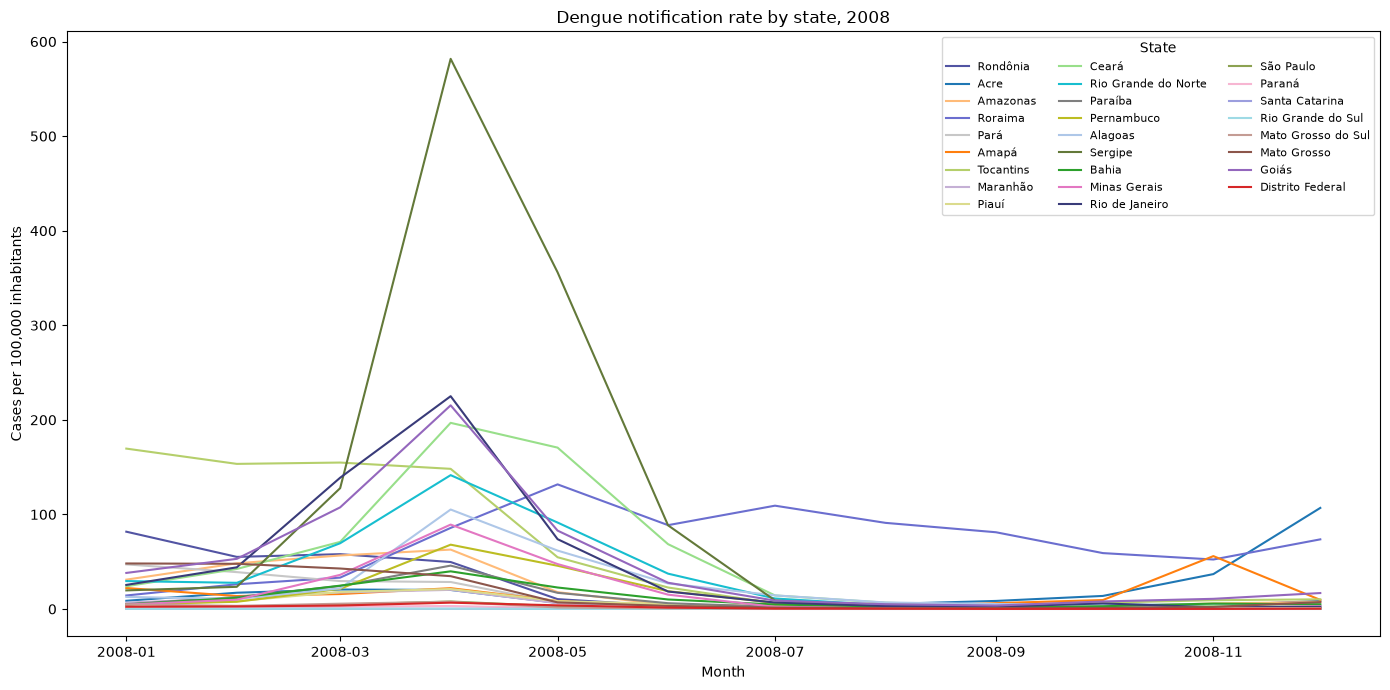

In [21]:
chosen_year = "2008"
fig, ax = viz.plot_state_timeseries(clean_dict[chosen_year], chosen_year, pop_lf)
plt.show()

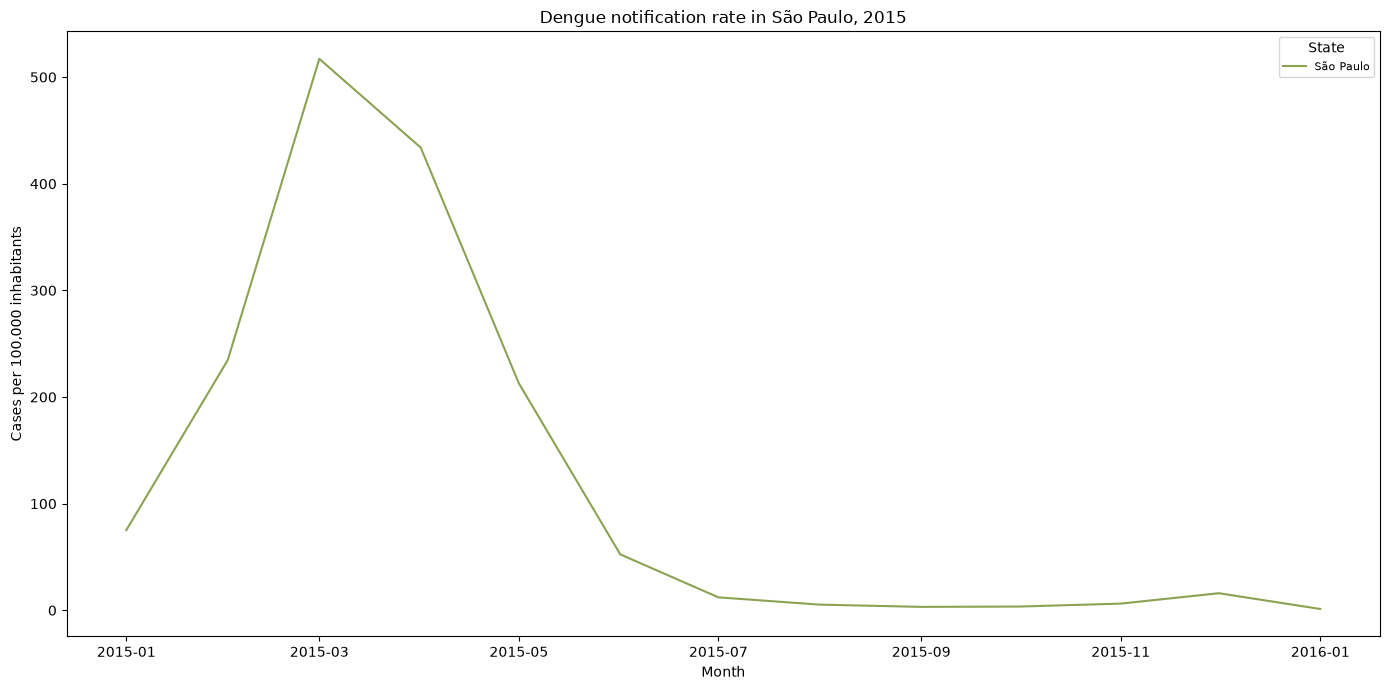

In [22]:
fig, ax = viz.plot_state_timeseries(clean_dict["2015"], "2015", pop_lf, state=35)  # São Paulo only
plt.show()

I just chose some years randomly, for the plots above, and found that there is pretty obvious seasonality, just from looking at the plots. This isn't really surprising, since there are well-known seasonal fluctuations in mosquito numbers.

## Yearly case counts
Check how much the number of cases per 100k population changes across years

In [23]:
yearly_case_counts = pl.concat(
    [
        pf.cases_per_capita(lf, pop_lf, year)
            .select("SG_UF_NOT", pl.lit(int(year)).alias("year"), "rate")
        for year, lf in clean_dict.items()
    ],
    how="vertical",
).with_columns(pl.col("SG_UF_NOT").replace_strict(pf.CODE_TO_UF).alias("state")) # 2-letter abbreviation, for plot labels

In [24]:
rates = yearly_case_counts.select("rate").collect().to_numpy()

# sanity check to make sure things correspond
# using data from yearly_case_counts and not some probably equivalent choice like len(clean_dict.keys()) for years
# because I specifically want to check this lazyframe/dataframe makes sense
num_years = yearly_case_counts.select(pl.col("year").unique().count()).collect().item()
num_states = yearly_case_counts.select(pl.col("SG_UF_NOT").unique().count()).collect().item()

assert(len(rates) == num_years * num_states)

#### Check distribution
Check the distribution of the rates; this is useful for knowing how to make downstream modeling decisions.

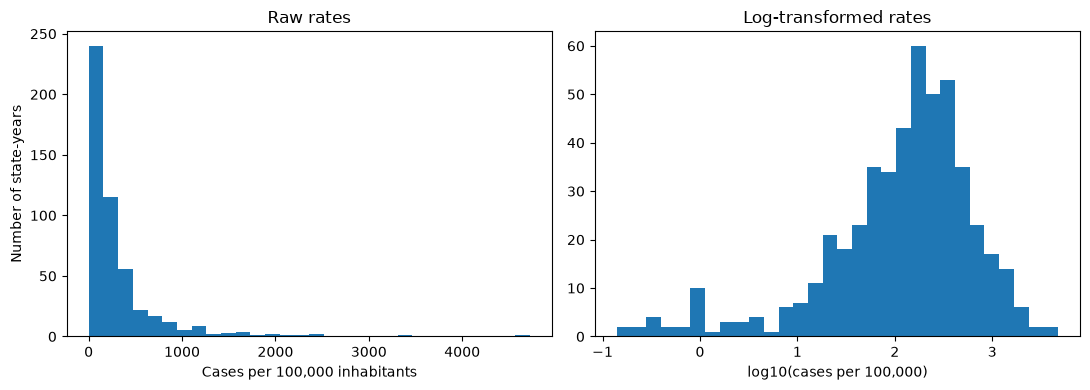

5th percentile: 2.0, 95th percentile: 1157.3
Ratio 95th/5th: 569


In [25]:
fig, (ax_raw, ax_log) = plt.subplots(1, 2, figsize=(11, 4))

ax_raw.hist(rates, bins=30) # bins is just a guess; interested in just being able to see distribution
ax_raw.set_title("Raw rates")
ax_raw.set_xlabel("Cases per 100,000 inhabitants")
ax_raw.set_ylabel("Number of state-years")

ax_log.hist(np.log10(rates), bins=30) # no +1 needed: no state-year has zero cases; log10 for readability
ax_log.set_title("Log-transformed rates")
ax_log.set_xlabel(r"log10(cases per 100,000)")

plt.tight_layout()
plt.show()

p5, p95 = np.percentile(rates, [5, 95])

# check how far apart things are in terms of orders of magnitue
print(f"5th percentile: {p5:.1f}, 95th percentile: {p95:.1f}")
print(f"Ratio 95th/5th: {p95 / p5:.0f}")

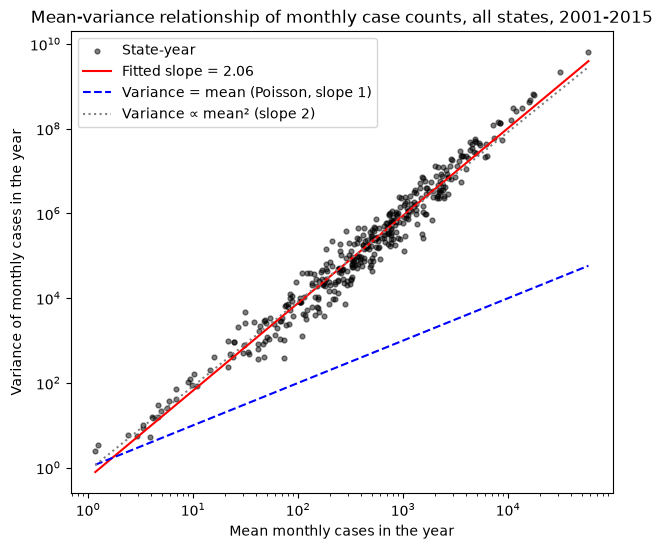

Fitted slope: 2.06
Median variance/mean ratio: 353


In [26]:
# Mean-variance plot: does the spread of monthly case counts grow with their level?
# One point per state-year: mean and variance of that year's 12 monthly counts.
#   slope 1 on log-log axes -> variance = mean (what a Poisson model assumes)
#   slope 2                 -> variance grows with mean^2: a log transform stabilises it
# Training years only (<= pf.TRAIN_END_YEAR), so modelling choices made from this plot don't use the test set
monthly_case_counts_all = pl.concat(
    [
        pf.cases_per_capita_monthly(lf, pop_lf, year)
        for year, lf in clean_dict.items()
        if int(year) <= pf.TRAIN_END_YEAR
    ],
    how="vertical",
)

mean_var = (
    monthly_case_counts_all
    .group_by("SG_UF_NOT", pl.col("month").dt.year().alias("year"))
    .agg(
        pl.col("cases").mean().alias("mean"),
        pl.col("cases").var().alias("variance"),
    )
    .filter(pl.col("mean") > 0) # log axes; a year with no cases has no meaningful spread
    .collect()
)

log_mean = np.log10(mean_var["mean"].to_numpy())
log_var = np.log10(mean_var["variance"].to_numpy())
slope, intercept = np.polyfit(log_mean, log_var, 1)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(mean_var["mean"], mean_var["variance"], s=12, alpha=0.5, color="black", label="State-year")

x = np.logspace(log_mean.min(), log_mean.max(), 100)
ax.plot(x, 10**intercept * x**slope, color="red", label=f"Fitted slope = {slope:.2f}")
ax.plot(x, x, color="blue", linestyle="--", label="Variance = mean (Poisson, slope 1)")
# slope-2 reference drawn through the centre of the data so it can be compared with the fitted line
centre_x, centre_y = log_mean.mean(), log_var.mean()
ax.plot(x, 10**(centre_y + 2 * (np.log10(x) - centre_x)), color="grey", linestyle=":", label="Variance ∝ mean² (slope 2)")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Mean monthly cases in the year")
ax.set_ylabel("Variance of monthly cases in the year")
ax.set_title(f"Mean-variance relationship of monthly case counts, all states, 2001-{pf.TRAIN_END_YEAR}")
ax.legend()
plt.show()

print(f"Fitted slope: {slope:.2f}")
print(f"Median variance/mean ratio: {(mean_var['variance'] / mean_var['mean']).median():.0f}")

The plots above suggest that a log transform is indeed appropriate. I chose log10 for interpretability, and did not add a +1 (or small value) to avoid log(0) as no state-year has zero cases, and this avoids adding distortion. At the state-month level a few states (eg SC and RS) do have months with zero cases, but none of the four states I model later do. Initially I did try log(rate + 1) but realized that this is both unnecessary and also distorts my data quite a bit as rates can have fairly low values, so 1 is too large a number to add anyway.

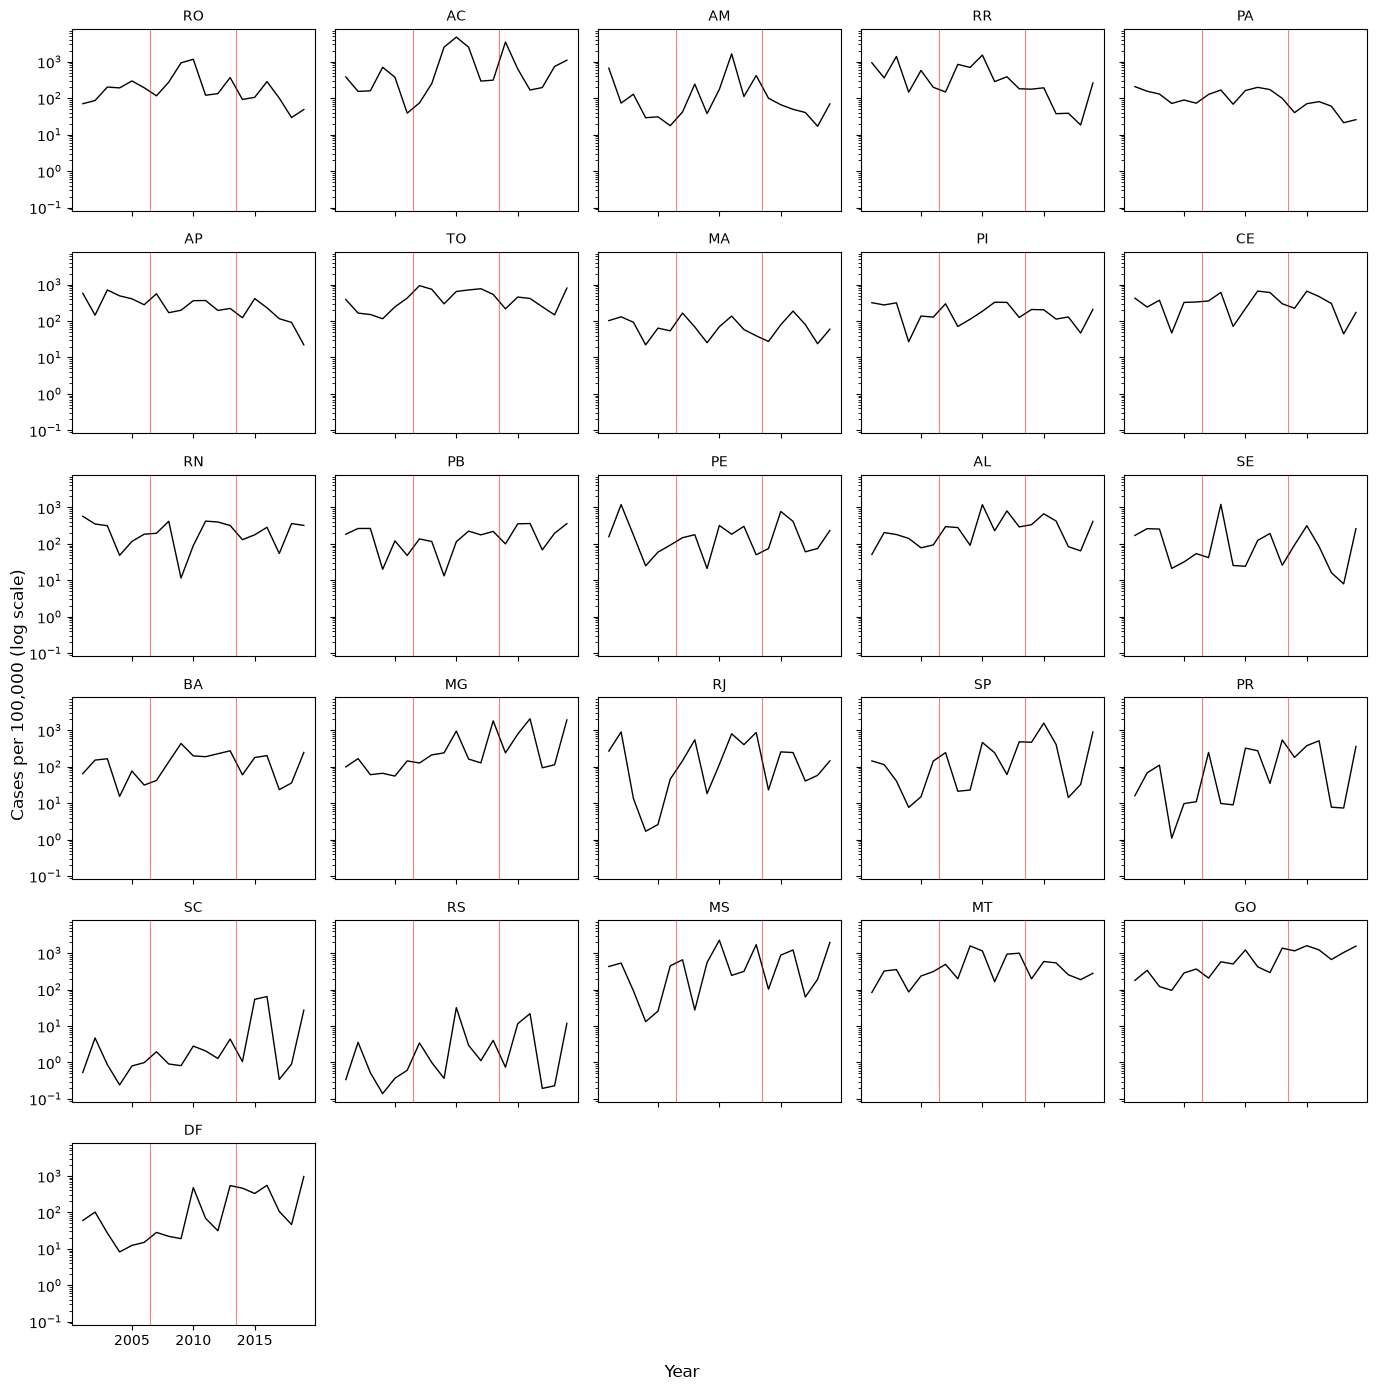

In [27]:
# plot state-level patterns: one panel per state (in IBGE code order, roughly north to south), on a log scale
state_rates = yearly_case_counts.sort("SG_UF_NOT", "year").collect()

fig, axes = plt.subplots(6, 5, figsize=(14, 14), sharex=True, sharey=True)
for ax, ((state,), group) in zip(axes.flat, state_rates.group_by("state", maintain_order=True)):
    ax.plot(group["year"], group["rate"], color="black", linewidth=1)
    ax.set_title(state, fontsize=10)
    for change_year in pf.SYSTEM_CHANGE_YEARS: # red line between the last year of the old system and the first of the new
        ax.axvline(change_year - 0.5, color="red", linewidth=0.8, alpha=0.5)
for ax in axes.flat[state_rates["state"].n_unique():]: # fewer states than panels
    ax.set_visible(False)

axes[0, 0].set_yscale("log") # sharey=True, so this applies to every panel
fig.supxlabel("Year")
fig.supylabel("Cases per 100,000 (log scale)")
plt.tight_layout()
plt.show()

The state-level plot is not that informative, as it's not very readable (too many states, too many years to be plotted nicely) but the point is to see consistent patterns over the years; for example, MT has consistently high cases compared to SC, which generally has low amounts of cases across all years. It also shows that no state ever reported a rate of zero across any of the years studied, which means the +1 in log(rate) is not necessary.

In [28]:
totals = []
for year, lf in clean_dict.items():
    
    year_pop = (pop_lf.filter(pl.col("year") == int(year)) # population of that year, all states
        .select(pl.col("population").sum())
        .collect()
        .item()
    )
    # append count per capita for that year
    totals.append(lf.select(pl.len()).collect().item() / year_pop)

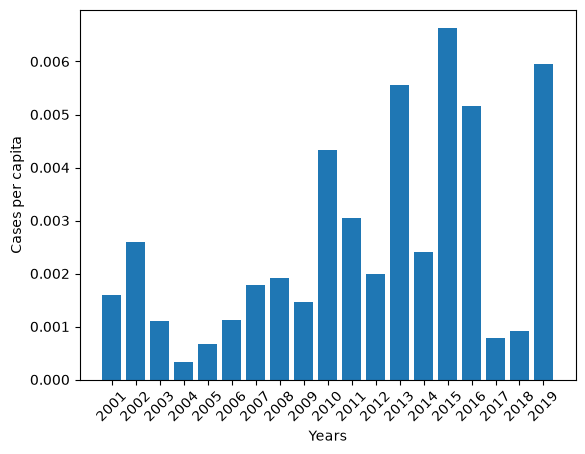

In [29]:
plt.bar(pf.DEFAULT_YEARS, totals)
plt.xticks(pf.DEFAULT_YEARS, rotation=45)
plt.xlabel("Years")

plt.ylabel("Cases per capita")
plt.show()

My aim (at least at the moment...) is not to formally classify whether there is an outbreak or epidemic, but I just wanted to see how the number of cases changes over time. We see clearly that 2010, 2013, 2015-2016 and 2019 were particularly bad years. It's hard to tell what is due to reporting differences vs natural occurrence.

On one hand, pre-2007 there are noticeably fewer cases on average, but it's hard to determine exactly why. Various factors go into dengue propagation, including things like land use, vegetation loss, mobility and travel patterns and socioeconomic conditions, according to [Sanabani (2025)](https://link.springer.com/article/10.1186/s12982-025-00937-4#citeas). From 2001 to 2019, the human development index increased from 0.691 in 2001 to 0.78 in 2019 (see [this chart](https://worldscorecard.com/scorecards/brazilian-scorecard/hdi/) based on the 2024 UN Human Development Report), which is likely to correlate with increases in infrastructure such as roads, which is linked to deforestation. Land use also continuously changes over time, though it varies across biomes ([Caballero et al (2023)](https://www.sciencedirect.com/science/article/pii/S0048969723049483#f0035)) and without a proper investigation, it is not possible to determine exactly how this has affected dengue transmission rates, especially within this relatively limited time frame, but it seems likely that clearing forests for agriculture and intensification of agricultural practices play some role.

It could also just be differences in reporting, or that those years were just less bad in terms of dengue propagation :-) There's probably no foolproof way to know for sure, but things I could check that might help me guess whether there were reporting differences:
- Changes in criterion used to classify cases (as in how many cases use lab tests vs other criteria)
- Changes in missingness patterns, but this can also just be random or a coincidence
- Changes in notification delay, though this might be misleading because more cases = more pressure on the system = more notification delay
- Checking how the number of severe cases changes and whether it follows a similar enough pattern to the above. It's likely someone will go to a hospital if they are in a life-threatening condition and it's probably quite recognizable at that point. But poor mobility can also stop people from going to a hospital, even if they're dying

For now, for simplicity, I am going to assume the reporting differences are small enough to ignore. But this is a limitation of my approach.


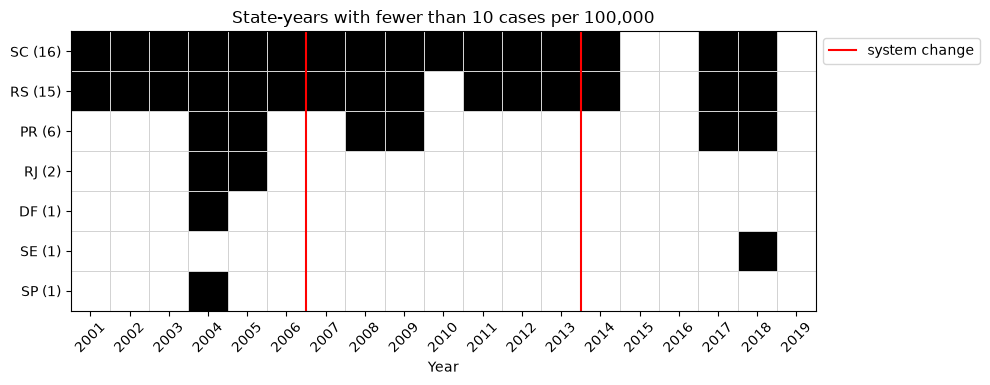

In [30]:
# Check that the very low counts don't follow a problematic-looking pattern (eg, due to reporting differences)
# One row per state with at least one low year (< 10 cases per 100,000), one column per year; black = low year.
# States are sorted by their number of low years (in brackets)
low_years = (
    yearly_case_counts
    .with_columns((pl.col("rate") < 10).cast(pl.Int8).alias("low"))
    .collect()
    .pivot(on="year", index="state", values="low", sort_columns=True)
    .with_columns(pl.sum_horizontal(pl.exclude("state")).alias("n_years"))
    .filter(pl.col("n_years") > 0)
    .sort(["n_years", "state"], descending=[True, False])
)
year_cols = [col for col in low_years.columns if col not in ("state", "n_years")]

# same style as viz.plot_column_presence
fig, ax = plt.subplots(figsize=(10, 0.35 * low_years.height + 1.5))
ax.pcolormesh(low_years.select(year_cols).to_numpy(), cmap="Greys", edgecolors="lightgrey", linewidth=0.5, vmin=0, vmax=1)
ax.invert_yaxis()
ax.set_xticks(np.arange(len(year_cols)) + 0.5, year_cols, rotation=45)
ax.set_yticks(np.arange(low_years.height) + 0.5, [f"{s} ({n})" for s, n in low_years.select("state", "n_years").iter_rows()])

for change_year in pf.SYSTEM_CHANGE_YEARS: # cell i spans x = i to i + 1, so x = index is the left edge of that year
    ax.axvline(year_cols.index(str(change_year)), color="red", linewidth=1.5,
               label="system change" if change_year == pf.SYSTEM_CHANGE_YEARS[0] else None)

ax.set_xlabel("Year")
ax.set_title("State-years with fewer than 10 cases per 100,000")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

Black = appears in the list of states with fewer than 10 cases per 100,000 for that year. The graph here doesn't concretely prove anything about changes in reporting patterns, but there don't seem to be massive dramatic changes around the system change dates. It also makes sense that in the particularly bad years, even the states with usually very low counts end up having high(er) counts. The fact that SP (Sao Paulo), one of the most densely populated states, appears here is somewhat surprising, but in 2004 there were indeed very few reported cases in general.

SC (Santa Catarina) and RS (Rio Grande do Sul) seem to have generally consistent low cases. These are the southernmost states where the average annual temperature is lowest, despite a generous amount of annual rainfall (see [this map](https://www.researchgate.net/figure/Annual-rainfall-and-annual-mean-air-temperature-in-Brazil-based-on-1950-1990-Alvares_fig53_334318966)). This might partly explain the low amount of cases as optimal temperatures for dengue-carrying (Aedes) mosquito development, according to [Liu et al (2023)](https://www.frontiersin.org/journals/cellular-and-infection-microbiology/articles/10.3389/fcimb.2023.1242173/full#s2) is around 25-30 degrees, whereas annual mean temperatures in these states can vary from around 22 to 12 degrees C. Furthermore, the authors state that temperature has been found to be positively correlated with dengue cases.

This is further supported by another study specifically looking at dengue epidemiology in Brazil, [Sanabani (2025)](https://link.springer.com/article/10.1186/s12982-025-00937-4#citeas), which states that 'The Southern region, which includes Paraná, Santa Catarina, and Rio Grande do Sul, has historically had the lowest dengue burden among Brazilian regions, primarily due to its temperate climate and colder winters, which are less favorable for the survival and reproduction of A. aegypti' 

## Cases per state over the years
After deciding that I want to make one model per state, for only specific states (see `02-UNIPLU_Exploratory.ipynb` for how I chose the states), I decided to check the yearly cases specifically for these states to see which years look like they could be epidemics (for a particular state) and to just get a better grasp of what I'm working with.

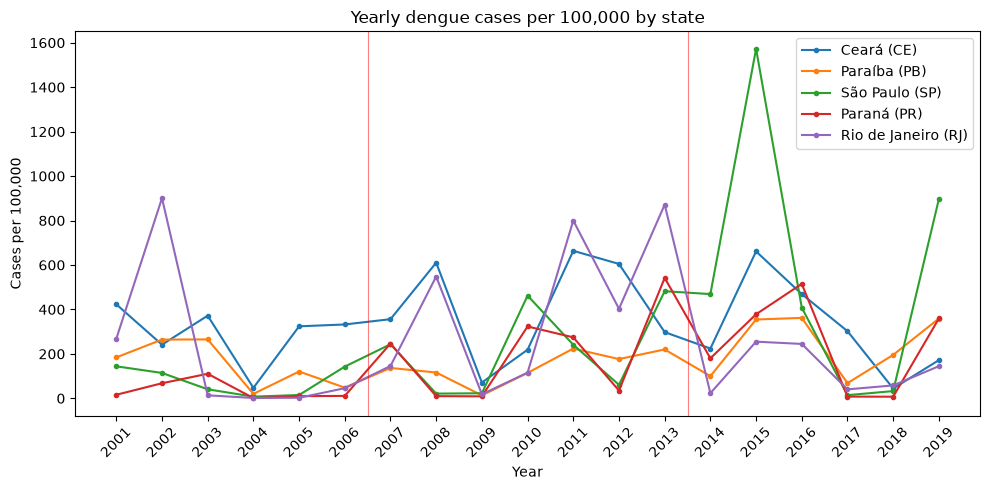

In [31]:
# yearly cases per 100,000 for the focus states (pf.FOCUS_STATES), with the system changes in red
focus_rates = yearly_case_counts.filter(pl.col("state").is_in(pf.FOCUS_STATES)).sort("year").collect()

fig, ax = plt.subplots(figsize=(10, 5))
for state in pf.FOCUS_STATES:
    group = focus_rates.filter(pl.col("state") == state)
    ax.plot(group["year"], group["rate"], marker="o", markersize=3, label=f"{viz.uf_label(state)} ({state})")

for change_year in pf.SYSTEM_CHANGE_YEARS:
    ax.axvline(change_year - 0.5, color="red", linewidth=0.8, alpha=0.5)

years = [int(y) for y in pf.DEFAULT_YEARS]
ax.set_xticks(years, years, rotation=45)
ax.set_xlabel("Year")
ax.set_ylabel("Cases per 100,000")
ax.set_title("Yearly dengue cases per 100,000 by state")
ax.legend()
plt.tight_layout()
plt.show()